### CRISP-DM · Fase 4: Modelado

Entrenamiento de una máquina de vectores de soporte (SVM) para clasificar la especie. El grupo de prueba no se usa en esta fase.

- **Entradas:** `crisp_dm/data/interim/train_clean.csv`, `crisp_dm/models/preprocessor.joblib`
- **Salidas:**
  - `crisp_dm/models/svm.joblib`: modelo final (preprocesador y SVM)
  - `crisp_dm/models/baseline.joblib`: modelo de referencia
  - `crisp_dm/data/processed/cv_results.csv`: resultados de la validación cruzada
  - `crisp_dm/figures/modeling_cv_results.png`: desempeño según los hiperparámetros

#### Librerías

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

#### Semilla

In [2]:
# Semilla para reproducibilidad. Puede modificarse o eliminarse.
SEED = 1

#### Rutas

Relativas a la carpeta del notebook.

In [3]:
INTERIM_DIR = Path("../data/interim")
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

#### Estilo de las figuras

In [4]:
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "axes.titlecolor": "#0b0b0b",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
    "font.size": 10,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

#### Carga de datos

In [5]:
train = pd.read_csv(INTERIM_DIR / "train_clean.csv")

TARGET = "species"
NUMERIC = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]
CATEGORICAL = ["island", "sex"]
FEATURES = NUMERIC + CATEGORICAL

X_train = train[FEATURES]
y_train = train[TARGET]

print(f"Registros: {len(X_train)}")

Registros: 273


#### Preprocesador

Copia sin ajustar del preprocesador de la fase anterior, para ajustarlo dentro de cada pliegue.

In [6]:
preprocessor = clone(joblib.load(MODELS_DIR / "preprocessor.joblib"))

#### Validación cruzada estratificada de 5 pliegues

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

#### Modelo de referencia

Predice siempre la especie más frecuente.

In [8]:
baseline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DummyClassifier(strategy="most_frequent")),
])
baseline_cv = cross_validate(baseline, X_train, y_train, cv=cv, scoring=["f1_macro", "accuracy"])

print(f"F1 macro: {baseline_cv['test_f1_macro'].mean():.3f}")
print(f"Exactitud: {baseline_cv['test_accuracy'].mean():.3f}")

F1 macro: 0.205
Exactitud: 0.443


#### Pipeline de SVM

La SVM se calibra con `CalibratedClassifierCV` para obtener la probabilidad de cada especie, necesaria para el criterio de revisión manual.

In [9]:
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", CalibratedClassifierCV(SVC(random_state=SEED), ensemble=False)),
])

#### Búsqueda de hiperparámetros

Kernel lineal y kernel RBF. Se elige la combinación con mayor F1 macro.

In [10]:
param_grid = [
    {
        "classifier__estimator__kernel": ["linear"],
        "classifier__estimator__C": [0.01, 0.1, 1, 10, 100],
    },
    {
        "classifier__estimator__kernel": ["rbf"],
        "classifier__estimator__C": [0.01, 0.1, 1, 10, 100],
        "classifier__estimator__gamma": [0.01, 0.1, 1],
    },
]

search = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    scoring={"f1_macro": "f1_macro", "accuracy": "accuracy"},
    refit="f1_macro",
    cv=cv,
    n_jobs=-1,
)
search.fit(X_train, y_train)

print(f"Mejores hiperparámetros: {search.best_params_}")
print(f"F1 macro: {search.best_score_:.4f}")

Mejores hiperparámetros: {'classifier__estimator__C': 1, 'classifier__estimator__kernel': 'linear'}
F1 macro: 1.0000


#### Resultados de la validación cruzada

In [11]:
res = pd.DataFrame(search.cv_results_)

cv_results = pd.DataFrame({
    "modelo": "svm",
    "kernel": res["param_classifier__estimator__kernel"],
    "C": res["param_classifier__estimator__C"],
    "gamma": res["param_classifier__estimator__gamma"].astype(object).where(res["param_classifier__estimator__gamma"].notna(), "—"),
    "f1_macro_mean": res["mean_test_f1_macro"],
    "f1_macro_std": res["std_test_f1_macro"],
    "accuracy_mean": res["mean_test_accuracy"],
    "accuracy_std": res["std_test_accuracy"],
    "rank": res["rank_test_f1_macro"],
})

baseline_row = pd.DataFrame([{
    "modelo": "baseline_most_frequent",
    "f1_macro_mean": baseline_cv["test_f1_macro"].mean(),
    "f1_macro_std": baseline_cv["test_f1_macro"].std(),
    "accuracy_mean": baseline_cv["test_accuracy"].mean(),
    "accuracy_std": baseline_cv["test_accuracy"].std(),
}])

cv_results = pd.concat([baseline_row, cv_results.sort_values("rank")], ignore_index=True)
cv_results = cv_results[[
    "modelo", "kernel", "C", "gamma",
    "f1_macro_mean", "f1_macro_std", "accuracy_mean", "accuracy_std", "rank",
]].round(4)
cv_results["rank"] = cv_results["rank"].astype("Int64")
cv_results.head(11)

,modelo,kernel,C,gamma,f1_macro_mean,f1_macro_std,accuracy_mean,accuracy_std,rank
0,baseline_most_frequent,NaN,NaN,NaN,0.2047,0.0033,0.4433,0.0103,<NA>
1,svm,linear,1.00,—,1.0000,0.0000,1.0000,0.0000,1
2,svm,linear,0.10,—,0.9955,0.0091,0.9964,0.0073,2
3,svm,rbf,10.00,0.01,0.9955,0.0091,0.9964,0.0073,2
4,svm,rbf,0.01,1.0,0.9952,0.0096,0.9963,0.0074,4
5,svm,rbf,1.00,1.0,0.9952,0.0096,0.9963,0.0074,4
6,svm,linear,10.00,—,0.9909,0.0111,0.9927,0.0090,6
7,svm,linear,100.00,—,0.9909,0.0111,0.9927,0.0090,6
8,svm,rbf,100.00,0.01,0.9909,0.0111,0.9927,0.0090,6
9,svm,rbf,1.00,0.1,0.9909,0.0111,0.9927,0.0089,6


#### Desempeño según los hiperparámetros

El modelo de referencia (F1 macro de 0.205) queda fuera de la escala.

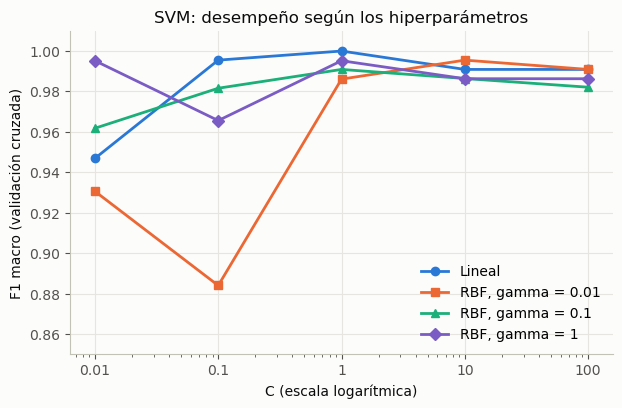

In [12]:
svm_rows = cv_results[cv_results["modelo"] == "svm"]
series = [("linear", "—", "Lineal", "#2a78d6", "o")] + [
    ("rbf", g, f"RBF, gamma = {g}", c, m)
    for g, c, m in [(0.01, "#eb6834", "s"), (0.1, "#1baf7a", "^"), (1, "#7b5cc4", "D")]
]

fig, ax = plt.subplots(figsize=(7, 4.2))
for kernel, gamma, label, color, marker in series:
    rows = svm_rows[(svm_rows["kernel"] == kernel) & (svm_rows["gamma"] == gamma)].sort_values("C")
    ax.plot(rows["C"].astype(float), rows["f1_macro_mean"], marker=marker, linewidth=2, color=color, label=label)
ax.set_xscale("log")
ax.set_xticks([0.01, 0.1, 1, 10, 100], ["0.01", "0.1", "1", "10", "100"])
ax.set_ylim(0.85, 1.01)
ax.set_xlabel("C (escala logarítmica)")
ax.set_ylabel("F1 macro (validación cruzada)")
ax.set_title("SVM: desempeño según los hiperparámetros")
ax.legend(loc="lower right")
fig.savefig(FIGURES_DIR / "modeling_cv_results.png")
plt.show()

#### Modelo final

In [13]:
final_model = search.best_estimator_
baseline.fit(X_train, y_train)

svm = final_model.named_steps["classifier"].calibrated_classifiers_[0].estimator
print(final_model)
print(f"Vectores de soporte por especie: {dict(zip(svm.classes_, svm.n_support_.tolist()))}")

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['culmen_length_mm',
                                                   'culmen_depth_mm',
                                                   'flipper_length_mm',
                                                   'body_mass_g']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['

#### Guardado de resultados

In [14]:
cv_results.to_csv(PROCESSED_DIR / "cv_results.csv", index=False)
joblib.dump(final_model, MODELS_DIR / "svm.joblib")
joblib.dump(baseline, MODELS_DIR / "baseline.joblib")

for path in [
    PROCESSED_DIR / "cv_results.csv",
    MODELS_DIR / "svm.joblib",
    MODELS_DIR / "baseline.joblib",
    FIGURES_DIR / "modeling_cv_results.png",
]:
    print(f"Guardado: {path}")

Guardado: ..\data\processed\cv_results.csv
Guardado: ..\models\svm.joblib
Guardado: ..\models\baseline.joblib
Guardado: ..\figures\modeling_cv_results.png
